# CNC anomaly detection: analysis
Week 1: the dataset, good vs bad spectra (graph 1) and the anomaly definition. All numbers below come from the code cells.

In [1]:
# CONFIG
IDLE_COUNTS = 100  # window RMS below this counts as machine idle; normal recordings have about 380 to 570 counts
GOOD, BAD = '#2a78d6', '#eb6834'

import sys
sys.path.insert(0, '..')
import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from sklearn.metrics import roc_auc_score
from src.features import AXES, BAND_BINS, FS, N_BANDS, N_PER_AXIS, WIN, features, index_recordings, load_recording

GROUP = ['machine', 'op', 'period']  # compare good and bad only inside one group, so only the label differs
# "counts" = raw values as stored in the h5 files. Their physical unit is UNVERIFIED (see Data facts in README.md).

## Dataset overview

In [2]:
idx = index_recordings()
assert idx['id'].is_unique
hours = idx.groupby('label')['n'].sum() / FS / 3600
idx['is_bad'] = idx['label'] == 'bad'
print(f"{len(idx)} recordings, {hours.sum():.2f} h; bad: {idx['is_bad'].sum()} recordings ({idx['is_bad'].mean():.1%}), {hours['bad']:.2f} h")
print(f"length: {(idx['n'] / FS).min():.1f} to {(idx['n'] / FS).max():.1f} s, median {(idx['n'] / FS).median():.1f} s\n")
for col in ['period', 'op']:
    t = idx.groupby(['machine', col])['is_bad'].agg(['sum', 'size'])
    print(f'Bad / total by machine and {col} (blank = no recordings):')
    print((t['sum'].astype(str) + '/' + t['size'].astype(str)).unstack().fillna('').to_string(), '\n')

1702 recordings, 24.81 h; bad: 70 recordings (4.1%), 0.78 h
length: 13.4 to 158.7 s, median 43.5 s

Bad / total by machine and period (blank = no recordings):
period  2019-02 2019-08 2020-02 2020-08 2021-02 2021-08
machine                                                
M01       19/78   7/198    0/58           2/154    6/31
M02       20/46   4/273    0/85    0/62   2/133    1/45
M03               3/267   0/129    0/37    4/62    2/44 

Bad / total by machine and op (blank = no recordings):
op       OP00  OP01  OP02  OP03  OP04  OP05  OP06  OP07  OP08  OP09  OP10  OP11  OP12  OP13  OP14
machine                                                                                          
M01      0/29  2/40  1/46  1/28  2/36  4/38  4/23  4/47  3/34  1/36  4/33  4/21  3/37  0/43  1/28
M02      1/27  3/54  2/54  1/29  3/32  2/44  0/30  3/55  4/46  0/43  2/46  2/33  2/44  0/51  2/56
M03      0/28  2/49  1/52  0/13  2/44  0/38  0/35  3/56  0/39  0/35  1/40  0/20  0/42  0/48       



## Data facts cross-check
Checks the facts in the README table against the files. RMS is the AC part (standard deviation), so the constant offset does not count as vibration.

In [3]:
# Reads all recordings once
keys, n_attrs = set(), 0
for p in idx['path']:
    with h5py.File(p) as f:
        keys |= set(f)
        n_attrs += len(f.attrs) + len(f['vibration_data'].attrs)
print(f'h5 keys: {sorted(keys)}, attributes: {n_attrs}, so the files hold no unit and no timestamps')
print(f"operations per machine: {idx.groupby('machine')['op'].nunique().to_dict()}; periods in filenames: {sorted(idx['period'].unique())}")
print(f"files: {idx['label'].value_counts().to_dict()}\n")

stats = pd.DataFrame([np.r_[x.mean(0), x.std(0), x.min(0), x.max(0)] for x in map(load_recording, idx['path'])],
                     columns=[f'{s}_{a}' for s in ['mean', 'rms', 'min', 'max'] for a in AXES], index=idx.index).astype(float)
print('value range per axis (counts):', {a: (stats[f'min_{a}'].min(), stats[f'max_{a}'].max()) for a in AXES})
df = idx.join(stats)
df['rms'] = np.sqrt((stats.filter(like='rms') ** 2).sum(axis=1))
print(stats.filter(like='mean').agg(['mean', 'min', 'max']).round(1).to_string())
print(f"Z offset is about {df['mean_Z'].mean():.0f} counts on every recording. If this is gravity, it fits mg, but that is a hint and not a verified unit.\n")

normal_by_op = df[~df['is_bad']].groupby('op')['rms'].median()
med = df.groupby(GROUP + ['label'])['rms'].median().unstack().dropna()
ratio = med['bad'] / med['good']
mixed = df[df.set_index(GROUP).index.isin(ratio.index)]
print(f'normal RMS, median per operation: {normal_by_op.min():.0f} to {normal_by_op.max():.0f} counts')
print(f'{len(ratio)} groups hold both labels ({len(mixed)} recordings, {mixed["is_bad"].sum()} bad)')
print(f'bad/good RMS ratio: median {ratio.median():.2f}, range {ratio.min():.2f} to {ratio.max():.2f}, above 1 in {(ratio > 1).sum()} of {len(ratio)} groups')

h5 keys: ['vibration_data'], attributes: 0, so the files hold no unit and no timestamps
operations per machine: {'M01': 15, 'M02': 15, 'M03': 14}; periods in filenames: ['2019-02', '2019-08', '2020-02', '2020-08', '2021-02', '2021-08']
files: {'good': 1632, 'bad': 70}



value range per axis (counts): {'X': (np.float64(-9234.0), np.float64(8657.0)), 'Y': (np.float64(-6552.0), np.float64(6023.0)), 'Z': (np.float64(-4753.0), np.float64(3090.0))}
      mean_X  mean_Y  mean_Z
mean     3.3    17.4 -1024.8
min     -8.6    -3.1 -1050.8
max     24.8    90.0 -1006.6
Z offset is about -1025 counts on every recording. If this is gravity, it fits mg, but that is a hint and not a verified unit.

normal RMS, median per operation: 378 to 568 counts
46 groups hold both labels (412 recordings, 68 bad)
bad/good RMS ratio: median 1.17, range 0.83 to 2.06, above 1 in 44 of 46 groups


## Sampling rate cross-check
The files have no timestamps, so this tests 2 kHz against Table 1 of the paper (p. 133). A wrong rate would shift every peak and length by the same factor.

In [4]:
# Table 1: spindle speed (Hz) and typical length (s) per operation
TABLE_1 = dict(OP00=(250, 132), OP01=(250, 29), OP02=(200, 42), OP03=(250, 77), OP04=(250, 64), OP05=(200, 18), OP06=(250, 91), OP07=(200, 24),
               OP08=(250, 37), OP09=(250, 102), OP10=(250, 45), OP11=(250, 59), OP12=(250, 46), OP13=(75, 32), OP14=(250, 34))
NFFT = 8192  # 0.24 Hz resolution, fine enough to separate 247 from 250 Hz
f8k = np.fft.rfftfreq(NFFT, 1 / FS)
rows = []
for op, (speed, seconds) in TABLE_1.items():
    good_op = idx[(idx['op'] == op) & ~idx['is_bad']]
    p = np.mean([welch(load_recording(q), FS, nperseg=NFFT, axis=0)[1] for q in good_op['path'][:20]], axis=0)
    near = np.abs(f8k - speed) < .1 * speed  # strongest Z peak within 10% of the table speed
    peak = f8k[near][p[near, 2].argmax()]
    rows.append(dict(op=op, table_hz=speed, peak_hz=peak, peak_ratio=peak / speed, table_s=seconds, data_s=good_op['n'].median() / FS, length_ratio=good_op['n'].median() / FS / seconds))
check = pd.DataFrame(rows).set_index('op')
print(check.round(3).to_string())
print(f"\nmedian ratio to Table 1: peak {check['peak_ratio'].median():.3f}, length {check['length_ratio'].median():.3f}")
print(f"good:bad file ratio {(~idx['is_bad']).sum() / idx['is_bad'].sum():.2f}; paper p. 134 gives 816:35 = {816 / 35:.2f}")

      table_hz  peak_hz  peak_ratio  table_s   data_s  length_ratio
op                                                                 
OP00       250  247.559       0.990      132  134.144         1.016
OP01       250  247.559       0.990       29   29.184         1.006
OP02       200  199.951       1.000       42   44.032         1.048
OP03       250  247.559       0.990       77   79.872         1.037
OP04       250  247.559       0.990       64   67.584         1.056
OP05       200  199.707       0.999       18   20.992         1.166
OP06       250  247.559       0.990       91   93.696         1.030
OP07       200  199.951       1.000       24   24.588         1.024
OP08       250  247.559       0.990       37   37.888         1.024
OP09       250  247.559       0.990      102  105.000         1.029
OP10       250  247.559       0.990       45   48.128         1.070
OP11       250  247.314       0.989       59   58.880         0.998
OP12       250  247.559       0.990       46   4

## Are bad recordings prepared differently?
The paper says the start and end of bad recordings were cut off during labelling (p. 135). This measures how much that matters, because a model must detect vibration and not how a file was cut.

In [5]:
F = {i: features(load_recording(p)) for i, p in mixed['path'].items()}
win_rms = {i: np.sqrt((f[:, ::N_PER_AXIS] ** 2).sum(axis=1)) for i, f in F.items()}  # one level per window, over all axes
is_bad = mixed['is_bad']

print(pd.crosstab([idx['period'], idx['label']], idx['dtype']).to_string())  # harmless: load_recording casts all to float32
lengths = mixed.groupby(GROUP + ['label'])['n'].median().unstack()
length = lengths['bad'] / lengths['good']
first = pd.Series({i: r[0] for i, r in win_rms.items()})
print(f'\nlength bad/good: median {length.median():.2f}, shorter in {(length < 1).sum()} of {len(length)} groups')
print(f'first window RMS (counts): good {first[~is_bad].median():.0f}, bad {first[is_bad].median():.0f}')
for limit in (50, IDLE_COUNTS, 200):
    quiet = pd.Series({i: (r < limit).mean() for i, r in win_rms.items()})
    print(f'idle below {limit} counts: recordings with any idle window: good {(quiet[~is_bad] > 0).mean():.0%}, bad {(quiet[is_bad] > 0).mean():.0%}; '
          f'AUROC of "less idle = bad" {roc_auc_score(is_bad, -quiet):.3f}')

share = []
for _, g in mixed.groupby(GROUP):
    limit = np.percentile(np.concatenate([win_rms[i] for i in g.index[~g['is_bad']]]), 99)
    share += [(win_rms[i] > limit).mean() for i in g.index[g['is_bad']]]
share = pd.Series(share)
print(f'\n{len(share)} bad recordings: median {share.median():.1%} of windows above the normal 99th percentile RMS of their group; '
      f'{(share < .05).sum()} recordings below 5%, {(share > .5).sum()} above 50%')

dtype          float32  float64  int64
period  label                         
2019-02 bad         39        0      0
        good        81        4      0
2019-08 bad          7        7      0
        good         0      724      0
2020-02 good         0       73    199
2020-08 good         0        0     99
2021-02 bad          0        0      8
        good         0        0    341
2021-08 bad          0        0      9
        good         0        2    109

length bad/good: median 0.82, shorter in 44 of 46 groups
first window RMS (counts): good 566, bad 712
idle below 50 counts: recordings with any idle window: good 71%, bad 3%; AUROC of "less idle = bad" 0.844
idle below 100 counts: recordings with any idle window: good 94%, bad 10%; AUROC of "less idle = bad" 0.926
idle below 200 counts: recordings with any idle window: good 100%, bad 44%; AUROC of "less idle = bad" 0.841

68 bad recordings: median 5.4% of windows above the normal 99th percentile RMS of their group; 34 recordi

## Graph 1: spectra good vs bad
Dotted lines are the FFT band edges in `src/features.py`. Each group counts once, and the geometric mean stops one loud group dominating a log scale.

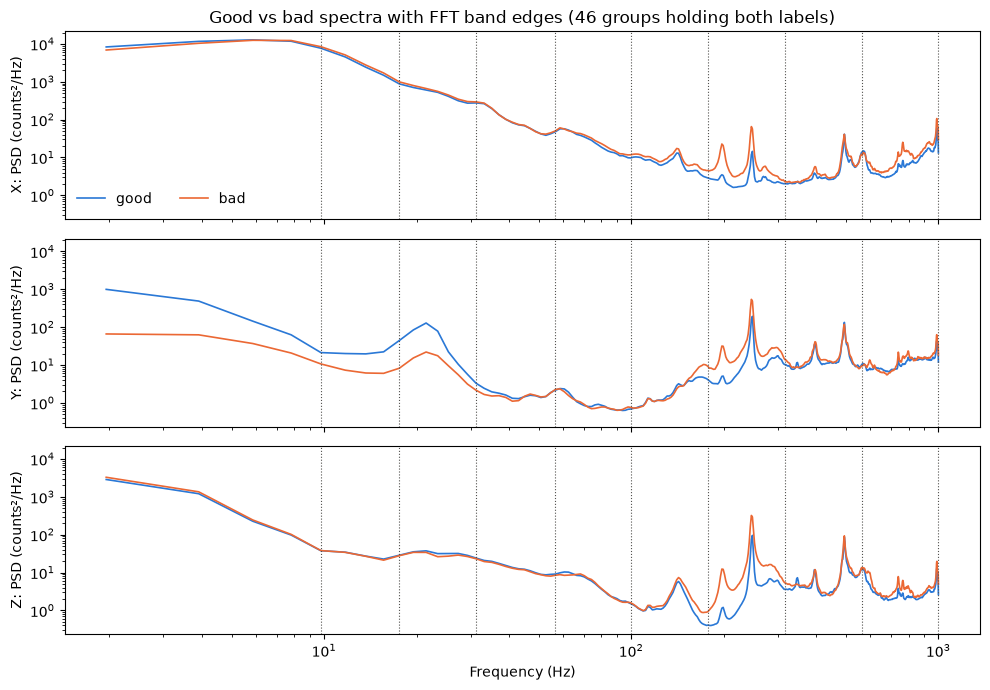

In [6]:
freq = np.fft.rfftfreq(WIN, 1 / FS)
psd = {i: welch(load_recording(p), FS, nperseg=WIN, axis=0)[1] for i, p in mixed['path'].items()}
group_psd = mixed.groupby(GROUP + ['label']).apply(lambda g: np.mean([psd[i] for i in g.index], axis=0), include_groups=False)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, sharey=True)
for i, (ax, a) in enumerate(zip(axes, AXES)):
    for lab, color in [('good', GOOD), ('bad', BAD)]:
        curves = np.array([group_psd[k + (lab,)][:, i] for k in ratio.index])
        ax.loglog(freq[1:], np.exp(np.log(curves).mean(axis=0))[1:], color=color, lw=1.2, label=lab)
    for b in BAND_BINS:
        ax.axvline(min(b, WIN // 2) * FS / WIN, color='#52514e', lw=.8, ls=':')
    ax.set(ylabel=f'{a}: PSD (counts²/Hz)')
axes[0].set_title(f'Good vs bad spectra with FFT band edges ({len(ratio)} groups holding both labels)')
axes[0].legend(frameon=False, ncol=2)
axes[2].set_xlabel('Frequency (Hz)')
fig.tight_layout()
plt.show()

In [7]:
# Same comparison on the real features: bad minus good log band energy, idle windows left out.
# dB = 10 * log10(P_bad / P_good) = 10 / ln(10) * (ln P_bad - ln P_good): definition of the decibel for power.
active = pd.DataFrame({i: f[win_rms[i] >= IDLE_COUNTS].mean(axis=0) for i, f in F.items()}).T
diff = active.join(mixed[GROUP + ['label']]).groupby(GROUP + ['label']).mean().unstack('label')
db = 10 / np.log(10) * (diff.xs('bad', axis=1, level='label') - diff.xs('good', axis=1, level='label'))
edges = BAND_BINS * FS / WIN
names = [f'{edges[b]:.0f}-{min(edges[b + 1], FS / 2):.0f} Hz' for b in range(N_BANDS)]
table = pd.DataFrame({a: [db[j * N_PER_AXIS + 3 + b].median() for b in range(N_BANDS)] for j, a in enumerate(AXES)}, index=names)
print('Median difference per feature band, bad - good (dB):\n', table.round(1).to_string())

Median difference per feature band, bad - good (dB):
                X    Y     Z
10-18 Hz     2.2 -0.8   0.9
18-31 Hz     1.6 -1.0   0.8
31-57 Hz     1.2 -0.2   0.2
57-100 Hz    1.3  0.2   0.1
100-178 Hz   1.1  1.3   1.1
178-316 Hz   9.9  8.6  10.5
316-562 Hz   1.3  0.7   1.6
562-1000 Hz  2.2  2.2   2.2


## Anomaly definition
A recording is an anomaly if it sits in a `bad/` folder. The dataset README calls these "Anomalous vibrational data" (line 28), and the paper calls them faulty processes. Normal means the `good/` recordings of the same operation. Models train on normal data only, and the bad labels are used only for evaluation and band selection, which still needs a decision.

**Cause.** The paper lists tool misalignment, chip clamping, chips in the chuck and tool breakage (p. 134). The labels come from an expert gauging the finished workpieces after each batch, and the paper admits some are wrong (p. 134).

**In the signal.** Bad recordings are louder: the median RMS ratio against good in the same group is 1.17, above 1 in 44 of 46 groups. Most of the extra energy is at 178 to 316 Hz, which is where the 200 and 250 Hz spindle speeds of most operations sit. That fits the paper, which finds anomalies at integer multiples of the spindle speed (p. 135). Median normal RMS runs from 378 to 568 counts across operations, much wider than the anomaly effect, so each operation gets its own model.

**What this means for evaluation.**
- Every window inherits its recording's label, yet in 34 of 68 bad recordings under 5% of windows are louder than the normal 99th percentile. The paper shows a mid-process snippet of a bad recording matching a good one (Fig. 9, p. 136). Window metrics will understate performance, so the recording-level result is the main one.
- Bad files had their start and end cut off (p. 135). That is why they are shorter and rarely contain idle windows, and "less idle means bad" alone reaches AUROC 0.926. Dropping idle windows (rule 2) removes this from the scores. Detection delay measured from the file start will still look too good.
- 39 of the 70 bad recordings are from 2019-02 and none from 2020, so any split must be checked for how many bad recordings it leaves to test on.


## Week 2: model results
Train on good 2019, set thresholds on good 2020, test on all of 2021. `python -m src.evaluate` logs the numbers to `results/metrics.csv`.

In [8]:
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from src.evaluate import ALL_RULES, load_data, score_test

idx2, F2 = load_data()
scores = {name: score_test(name, idx2, F2, **ALL_RULES) for name in ['rms', 'mahalanobis', 'pca']}
is_bad2 = lambda i: idx2.loc[i, 'label'] == 'bad'
windows = lambda s, bad: np.concatenate([v for i, v in s.items() if is_bad2(i) == bad])
print(idx2.groupby(['split', 'label']).size().to_string())

split  label
test   bad       17
       good     452
train  good     809
val    good     371


## Graph 2: score histogram
A score of 1 is the threshold: the 99th percentile of normal validation scores for that operation.

above threshold: normal windows 2.07% (target 1%), bad windows 37.98%


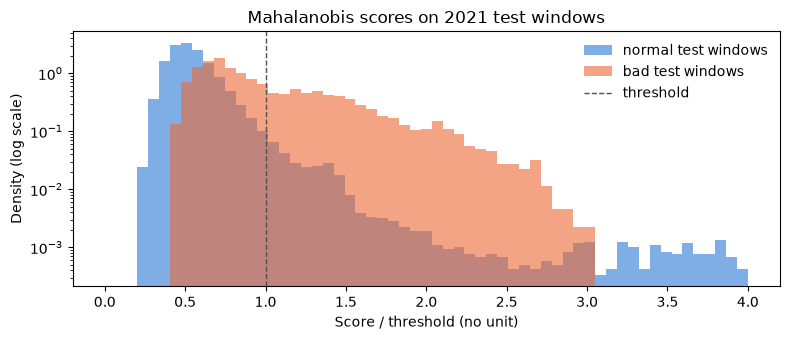

In [9]:
maha = scores['mahalanobis']
normal, bad = windows(maha, False), windows(maha, True)
print(f'above threshold: normal windows {(normal > 1).mean():.2%} (target 1%), bad windows {(bad > 1).mean():.2%}')

bins = np.linspace(0, 4, 60)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(normal, bins, density=True, color=GOOD, alpha=.6, label='normal test windows')
ax.hist(bad, bins, density=True, color=BAD, alpha=.6, label='bad test windows')
ax.axvline(1, color='#52514e', ls='--', lw=1, label='threshold')
ax.set(yscale='log', title='Mahalanobis scores on 2021 test windows', xlabel='Score / threshold (no unit)', ylabel='Density (log scale)')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Graph 3: ROC and PR curves
Recording level, where each recording scores its 95th percentile window. The test set has 17 bad recordings, so one recording moves recall by 5.9 points.

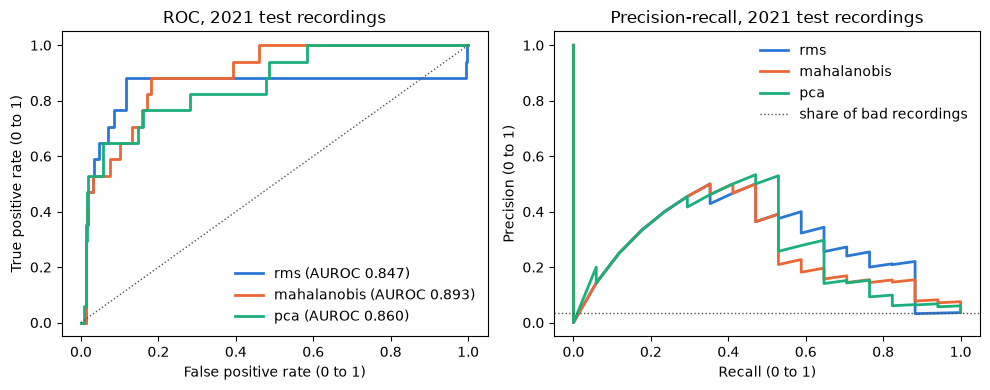

In [10]:
COLORS = dict(rms='#2a78d6', mahalanobis='#eb6834', pca='#1baf7a')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, s in scores.items():
    y = [is_bad2(i) for i in s]
    p95 = [np.percentile(v, 95) for v in s.values()]
    fpr, tpr, _ = roc_curve(y, p95)
    precision, recall, _ = precision_recall_curve(y, p95)
    axes[0].plot(fpr, tpr, color=COLORS[name], lw=2, label=f'{name} (AUROC {roc_auc_score(y, p95):.3f})')
    axes[1].plot(recall, precision, color=COLORS[name], lw=2, label=name)
axes[0].plot([0, 1], [0, 1], color='#52514e', ls=':', lw=1)
axes[1].axhline(np.mean(y), color='#52514e', ls=':', lw=1, label='share of bad recordings')
axes[0].set(title='ROC, 2021 test recordings', xlabel='False positive rate (0 to 1)', ylabel='True positive rate (0 to 1)')
axes[1].set(title='Precision-recall, 2021 test recordings', xlabel='Recall (0 to 1)', ylabel='Precision (0 to 1)')
for ax in axes:
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()